<a href="https://colab.research.google.com/github/remifakunle59-design/Forest-Carbon-Analysis/blob/main/02_cloud_landsat_analyses_for_lulucf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cloud-based Landsat analysis of lulucf, southeastern Osun State, Nigeria

**Question:** Can cloud-hosted Landsat data, read without downloading scenes, and assessed the land-cover change found in my MSc thesis (1985-2020)?

**Step**
1. Search Landsat Collection 2 Level-2 on Microsoft Planetary Computer (STAC) for the dry season of each thesis map year.
2. Mask clouds, compute NDVI and build median composites with Xarray and Dask.
3. Read NDVI at my 2020 ground-truth points and compare each land-cover class with dense forest in the same year.
4. Test a supervised classification (random forest) trained on the ground-truth points, with leave-one-out cross-validation.

**Limitations**
- Different sensors (Landsat 4/5/7/8), seasons and haze between years: absolute NDVI is not comparable across years.
- No usable Landsat scene was found for 1992 in this archive.
- Only about 40 ground-truth points (3-8 per class), all from around 2020.
- This is a workflow demonstration and a consistency check, not a replacement for the thesis classification and accuracy assessment.

In [1]:
!pip install -q pystac-client planetary-computer odc-stac rioxarray

In [2]:
import warnings, logging
warnings.filterwarnings("ignore")                       # hide harmless GDAL/Dask warnings
logging.getLogger("rasterio").setLevel(logging.ERROR)
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import planetary_computer as pc
from pystac_client import Client
from odc.stac import load
from pyproj import Transformer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)
bbox = [4.30, 6.90, 5.05, 7.92]   # search box, larger than the study-area boundary: west, south, east, north (degrees)

## 0. Study-area boundary

Satellite data are read for a rectangular box, but my study area has an irregular border (ten LGAs of southeastern Osun State). I uploaded the boundary shapefile **once** here (select all its files together: .shp, .shx, .dbf, .prj). It is used below to clip the maps and to compute area shares inside the true boundary. Ground-truth points are still read from the unclipped composites, so no point is lost at the border.

In [3]:
import os
import geopandas as gpd
import rioxarray  # adds .rio to xarray objects
from google.colab import files

uploaded = files.upload()          # choose ALL files of the shapefile at once
shp = [f for f in uploaded if f.lower().endswith(".shp")][0]
area = gpd.read_file(shp)
if area.crs is None:
    raise ValueError("Boundary CRS missing: upload the .prj file or supply the verified source CRS; do not assume EPSG:4326.")
area_utm = area.to_crs("EPSG:32631").dissolve()     # one polygon, metres
boundary_km2 = float(area_utm.area.iloc[0]) / 1e6
thesis_2020_km2 = 3271.55  # provisional: replace with verified thesis extent if needed
print("Boundary area vs provisional thesis area:", round(boundary_km2, 2), round(thesis_2020_km2, 2), "km²")
if abs(boundary_km2 - thesis_2020_km2) > 0.01 * thesis_2020_km2:
    print("WARNING: different spatial extents. Do not compare mapped area shares as if boundaries matched.")
print("Boundary features:", len(area), "| area inside boundary:",
      round(float(area_utm.area.iloc[0]) / 1e6), "km2")
w, s, e, n = area.to_crs("EPSG:4326").total_bounds
print("Boundary box (W, S, E, N):", [round(v, 3) for v in (w, s, e, n)])
if w < bbox[0] or s < bbox[1] or e > bbox[2] or n > bbox[3]:
    print("WARNING: the boundary extends beyond the search box; enlarge bbox above.")

def clip_to_area(obj):
    # everything outside the study-area boundary becomes NaN; crop to its extent
    return obj.rio.write_crs("EPSG:32631").rio.clip(area_utm.geometry, area_utm.crs, drop=True)

Saving SE_Osun_State.cpg to SE_Osun_State.cpg
Saving SE_Osun_State.dbf to SE_Osun_State.dbf
Saving SE_Osun_State.prj to SE_Osun_State.prj
Saving SE_Osun_State.sbn to SE_Osun_State.sbn
Saving SE_Osun_State.sbx to SE_Osun_State.sbx
Saving SE_Osun_State.shp to SE_Osun_State.shp
Saving SE_Osun_State.shp.FAKUNLES.20768.20908.sr.lock to SE_Osun_State.shp.FAKUNLES.20768.20908.sr.lock
Saving SE_Osun_State.shp.xml to SE_Osun_State.shp.xml
Saving SE_Osun_State.shx to SE_Osun_State.shx
Boundary area vs provisional thesis area: 4258.75 3271.55 km²
Boundary features: 10 | area inside boundary: 4259 km2
Boundary box (W, S, E, N): [np.float64(4.358), np.float64(6.967), np.float64(5.001), np.float64(7.865)]


## 1. Which scenes exist?

Each map year gets a dry-season window (December to April) and the Landsat sensors that were operating. Scenes with less than 60% cloud cover are kept.

In [4]:
windows = {
    1985: (["landsat-4", "landsat-5"], "1984-12-01/1985-05-31"),
    1992: (["landsat-4", "landsat-5"], "1991-12-01/1992-04-30"),
    1999: (["landsat-5", "landsat-7"], "1999-01-01/1999-12-31"),
    2006: (["landsat-5", "landsat-7"], "2005-12-01/2006-04-30"),
    2013: (["landsat-7"], "2012-12-01/2013-04-30"),
    2020: (["landsat-8"], "2019-12-01/2020-04-30"),
}
MAX_CLOUD = 60

def find_scenes(year):
    plats, dt = windows[year]
    items = list(catalog.search(
        collections=["landsat-c2-l2"], bbox=bbox, datetime=dt,
        query={"platform": {"in": plats}, "eo:cloud_cover": {"lt": MAX_CLOUD}},
    ).items())
    return sorted(items, key=lambda i: i.properties["eo:cloud_cover"])

for y in windows:
    print(y, "->", len(find_scenes(y)), "scenes found")

1985 -> 6 scenes found
1992 -> 0 scenes found
1999 -> 7 scenes found
2006 -> 13 scenes found
2013 -> 14 scenes found
2020 -> 30 scenes found


## 2. NDVI composites

For each year with scenes: I loaded red, near-infrared and the quality band, keep clear pixels only, convert to surface reflectance (scale 0.0000275, offset -0.2), compute NDVI = (NIR - red) / (NIR + red) and take the median over the best (least cloudy) scenes. Data are loaded with Dask and computed at the end.

1985 scenes used: 6 [('landsat-5', '1984-12-18', 0), ('landsat-5', '1984-12-11', 0), ('landsat-5', '1984-12-11', 2), ('landsat-5', '1984-12-18', 4), ('landsat-5', '1985-05-04', 19), ('landsat-5', '1985-01-28', 55)]
1985 valid pixels: 99.9 % | mean NDVI: 0.4
1999 scenes used: 6 [('landsat-5', '1999-02-11', 0), ('landsat-7', '1999-12-13', 2), ('landsat-7', '1999-12-13', 11), ('landsat-7', '1999-10-26', 18), ('landsat-5', '1999-02-11', 24), ('landsat-7', '1999-11-18', 28)]
1999 valid pixels: 84.7 % | mean NDVI: 0.71
2006 scenes used: 6 [('landsat-7', '2005-12-29', 0), ('landsat-7', '2005-12-29', 0), ('landsat-7', '2005-12-20', 0), ('landsat-7', '2005-12-13', 0), ('landsat-7', '2005-12-04', 12), ('landsat-7', '2005-12-20', 16)]
2006 valid pixels: 82.3 % | mean NDVI: 0.5
2013 scenes used: 6 [('landsat-7', '2013-01-01', 0), ('landsat-7', '2013-01-01', 0), ('landsat-7', '2012-12-16', 0), ('landsat-7', '2012-12-23', 1), ('landsat-7', '2012-12-23', 10), ('landsat-7', '2013-01-08', 11)]
2013 val

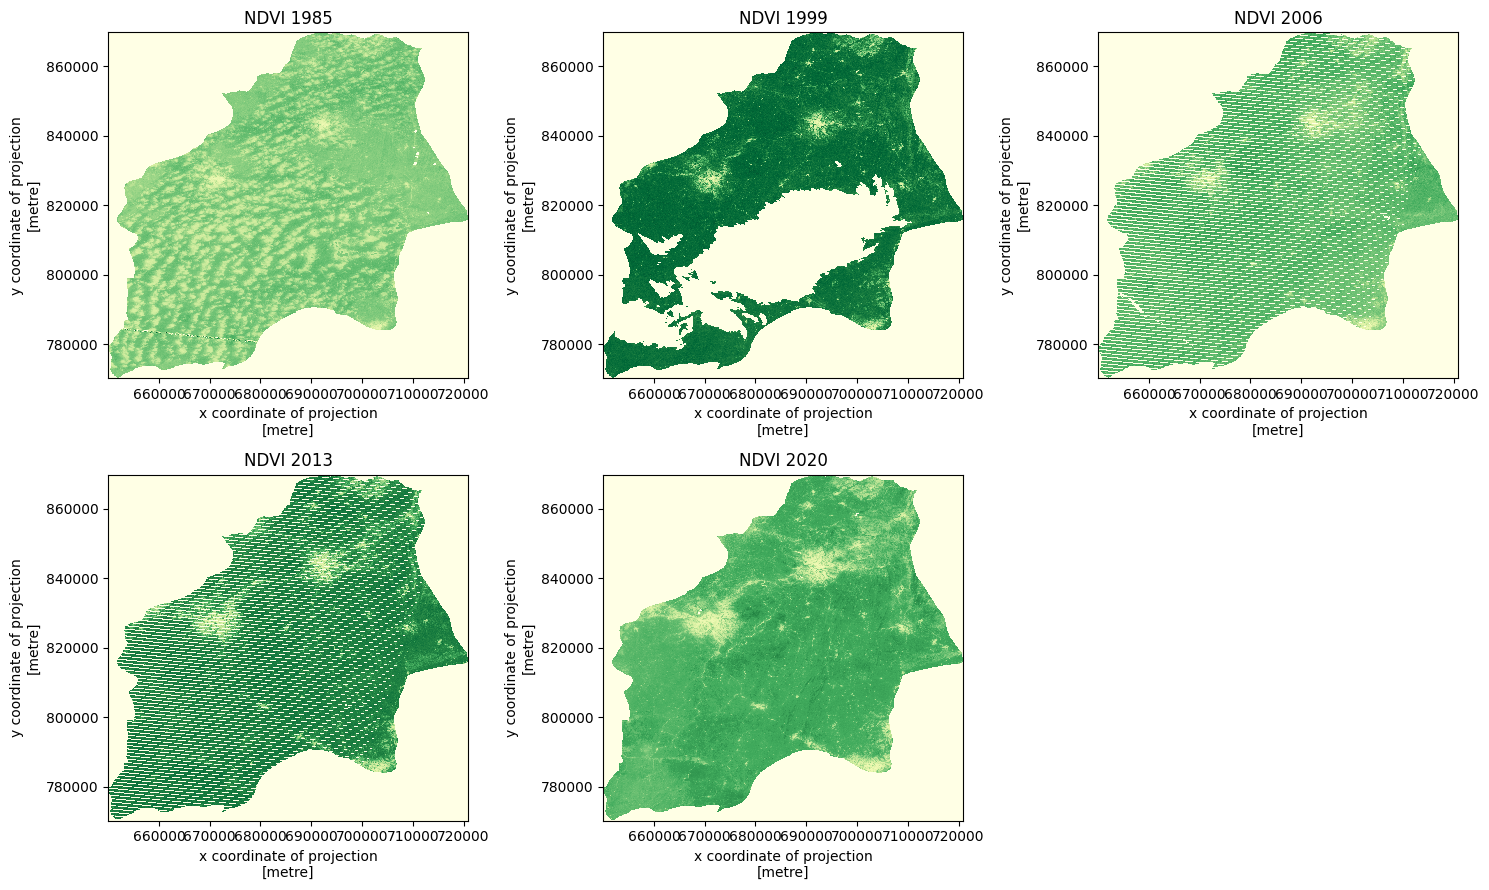

In [5]:
def ndvi_composite(year, n=6):
    items = find_scenes(year)[:n]
    if not items:
        raise ValueError(f"No suitable scenes found for {year}; expand search dates or inspect coverage.")
    print(year, "scenes used:", len(items),
          [(i.properties["platform"], i.datetime.strftime("%Y-%m-%d"),
            round(i.properties["eo:cloud_cover"])) for i in items])
    ds = load(items, bands=["red", "nir08", "qa_pixel"], bbox=bbox,
              crs="EPSG:32631", resolution=30, chunks={})
    clear = ((ds.qa_pixel & 0b11111) == 0) & (ds.red > 0) & (ds.nir08 > 0)   # also drop no-data edges
    red = (ds.red * 0.0000275 - 0.2).where(clear)
    nir = (ds.nir08 * 0.0000275 - 0.2).where(clear)
    ndvi = (nir - red) / (nir + red)
    return ndvi.median("time", skipna=True).compute()

years_with_scenes = [y for y in windows if len(find_scenes(y)) > 0]
ndvi_old = {}
for y in years_with_scenes:
    ndvi_old[y] = ndvi_composite(y)
    valid = float(ndvi_old[y].notnull().mean()) * 100
    print(y, "valid pixels:", round(valid, 1), "% | mean NDVI:",
          round(float(ndvi_old[y].mean()), 2))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax in axes.flat:
    ax.axis("off")
for ax, (y, arr) in zip(axes.flat, ndvi_old.items()):
    ax.axis("on")
    clip_to_area(arr).plot(ax=ax, vmin=0, vmax=0.9, cmap="YlGn", add_colorbar=False)
    ax.set_title(f"NDVI {y}")
plt.tight_layout()
plt.show()

**Reading the composites.** Mean NDVI jumps between years (it does not follow the forest loss in the thesis). That comes from season, haze and sensor differences, for example Landsat 7 stripe gaps in 2006 and 2013, December haze (Harmattan) in 1985, and cloud gaps in 1999. Absolute NDVI is therefore not compared between years below. The next step compares land-cover classes with each other inside the same year.

## 3. Ground-truth points

Field points from my thesis fieldwork (around 2020), one class per point. Coordinates are latitude, longitude. Points outside the study box are dropped.

In [6]:
raw = {
 "Urban": [(7.488625268039872,4.558864966075811),(7.476711299086911,4.5966304664952915),
           (7.621747704731985,4.73000303497964),(7.685539638821532,4.812980556925489),
           (7.525257183498923,4.826026821573927),(7.519756111042367,4.522342013501397),
           (7.584591017335293,4.622807114263536),(7.4985025580367,4.591377707784486)],
 "Rock": [(7.569764864932427,4.901290197250624),(7.5678429329391825,4.589379305036962),
          (7.523560606707938,4.827163626374622)],
 "Dense": [(7.290542,4.681429),(7.374636,4.757359),(7.574767,4.826328),
           (7.380620430074522,4.7532981873453),(7.367482636022572,4.5980521950232385),
           (7.169030715839153,4.418826656282485),(7.498653173491989,4.7921240728968195)],
 "Light": [(7.412285,4.872518),(7.449931,4.832023),(7.604478287416747,4.831193288350328),
           (7.431615753032943,4.6744365974364195),(7.566578951017598,4.788209775216805),
           (7.546386969790382,4.741799690330941)],
 "Plantation": [(7.521449,4.857965),(7.51559017762442,4.7131352969431335),
                (7.5717670915602335,4.630666888549262),(7.555060260744655,4.650561118575805),
                (7.616533921646177,4.6797990713259745),(7.4784168839571885,4.66060189114534),
                (7.3455755786415295,4.610032970022593),(7.493372054161735,4.671191118369842)],
 "Cropland": [(7.686581104964765,4.7892909539648905),(7.766395366743649,4.725869248420497),
              (7.731146461444127,4.85782490083182),(7.613043424911679,4.691165269149717),
              (7.527933158472189,4.598860761185744),(7.560391476779276,4.883791355053789),
              (7.464740342599741,4.6082796732213644),(7.581300515552431,4.627617203769058)],
}
pts = pd.DataFrame([(c, lat, lon) for c, p in raw.items() for lat, lon in p],
                   columns=["class", "lat", "lon"])
inside = ((pts.lon >= bbox[0]) & (pts.lon <= bbox[2]) &
          (pts.lat >= bbox[1]) & (pts.lat <= bbox[3]))
print("Dropped (outside the study box):", int((~inside).sum()))
pts = pts[inside].reset_index(drop=True)
print(pts["class"].value_counts())

tr = Transformer.from_crs("EPSG:4326", "EPSG:32631", always_xy=True)
px, py = tr.transform(pts.lon.values, pts.lat.values)    # longitude first, then latitude
xs = xr.DataArray(px, dims="pt")
ys = xr.DataArray(py, dims="pt")

Dropped (outside the study box): 0
class
Urban         8
Cropland      8
Plantation    8
Dense         7
Light         6
Rock          3
Name: count, dtype: int64


## 4. NDVI at the points, relative to dense forest

NDVI is averaged over 3 x 3 pixels (90 m) around each point to reduce GPS and registration error. Haze, season and sensor affect all points in a year alike, so each class is expressed relative to the dense-forest points of the same year (1.00 = same as dense forest). Error bars are standard errors (SD divided by the square root of the number of points), an approximation that ignores the uncertainty of the dense-forest mean.

Mean NDVI per class:
            ndvi_1985  ndvi_1999  ndvi_2006  ndvi_2013  ndvi_2020
class                                                            
Cropland         0.41       0.74       0.51       0.65       0.51
Dense            0.39       0.78       0.51       0.71       0.57
Light            0.43       0.77       0.49       0.70       0.58
Plantation       0.39       0.76       0.54       0.69       0.56
Rock             0.42       0.73       0.50       0.65       0.52
Urban            0.31       0.52       0.37       0.44       0.32

Relative to dense forest:
            ndvi_1985  ndvi_1999  ndvi_2006  ndvi_2013  ndvi_2020
class                                                            
Cropland         1.07       0.95       0.99       0.92       0.90
Dense            1.00       1.00       1.00       1.00       1.00
Light            1.10       0.98       0.97       1.00       1.02
Plantation       1.02       0.98       1.05       0.98       0.98
Rock             1.09       

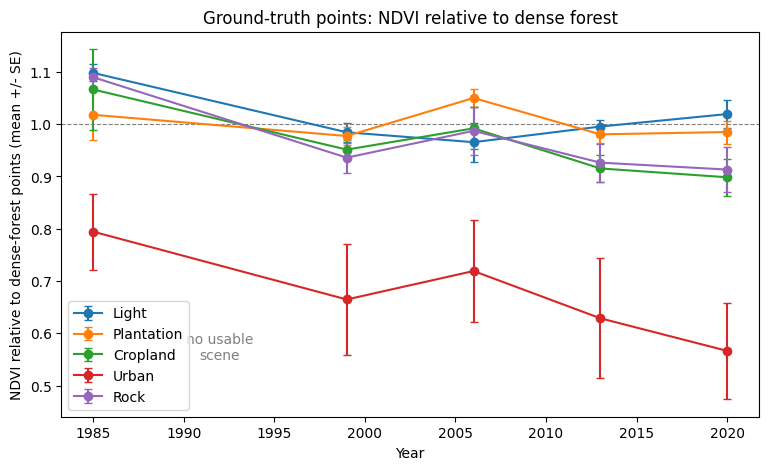

In [7]:
for y, arr in ndvi_old.items():
    smooth = arr.rolling(x=3, y=3, center=True, min_periods=1).mean()
    pts[f"ndvi_{y}"] = smooth.sel(x=xs, y=ys, method="nearest").values

years = sorted(ndvi_old)
cols = [f"ndvi_{y}" for y in years]
means = pts.groupby("class")[cols].mean()
ratio = means / means.loc["Dense"]
se_ratio = pts.groupby("class")[cols].sem() / means.loc["Dense"]

print("Mean NDVI per class:")
print(means.round(2))
print("\nRelative to dense forest:")
print(ratio.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
for c in ["Light", "Plantation", "Cropland", "Urban", "Rock"]:
    ax.errorbar(years, ratio.loc[c].values, yerr=se_ratio.loc[c].values,
                marker="o", capsize=3, label=c)
ax.axhline(1, color="grey", lw=0.8, ls="--")
ax.text(1992, 0.55, "no usable\nscene", ha="center", color="grey")
ax.set_xlabel("Year")
ax.set_ylabel("NDVI relative to dense-forest points (mean +/- SE)")
ax.set_title("Ground-truth points: NDVI relative to dense forest")
ax.legend(loc="lower left")
plt.show()

**Interpretation.** Urban points are consistently less vegetated than dense forest and fall further over time, consistent with the urban expansion in the thesis land-cover maps. Cropland points look forest-like in the 1985 composite and lower by 2020. Plantation, light-forest and rock points show no clear trend. NDVI saturates over closed canopy and cannot separate forest from tree plantations, so these curves support, but do not replace, the thesis classification. With only 3-8 points per class, differences of about 0.05 are within noise, and the 1985 composite is affected by dry-season haze (narrow NDVI range).

## 5. Supervised classification test (random forest)

Features are six Landsat 8 surface-reflectance bands (blue, green, red, NIR, SWIR1, SWIR2) and NDVI from a 2020 dry-season composite, read at the ground-truth points. A random forest is evaluated with **leave-one-out cross-validation** (each point is predicted by a model trained on all the others).

First with all six classes, then with three classes that Landsat spectra can reasonably separate: tree cover (dense forest, light forest, plantation), cropland, and built-up/bare (urban, rock).

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix
from matplotlib.colors import ListedColormap

bands = ["blue", "green", "red", "nir08", "swir16", "swir22"]
items = find_scenes(2020)[:6]
if not items:
    raise ValueError("No suitable 2020 scenes found for classification.")
ds = load(items, bands=bands + ["qa_pixel"], bbox=bbox, crs="EPSG:32631",
          resolution=30, chunks={})
clear = ((ds.qa_pixel & 0b11111) == 0) & (ds.red > 0) & (ds.nir08 > 0)   # also drop no-data edges
comp = xr.Dataset({b: (ds[b] * 0.0000275 - 0.2).where(clear).median("time", skipna=True)
                   for b in bands}).compute()
comp["ndvi"] = (comp.nir08 - comp.red) / (comp.nir08 + comp.red)
feat_names = list(comp.data_vars)

smooth = comp.rolling(x=3, y=3, center=True, min_periods=1).mean()
X = np.column_stack([smooth[v].sel(x=xs, y=ys, method="nearest").values for v in feat_names])
labels = ["Dense", "Light", "Plantation", "Cropland", "Urban", "Rock"]
codes = {c: i for i, c in enumerate(labels)}
y6 = pts["class"].map(codes).values
ok = ~np.isnan(X).any(axis=1)
X, y6 = X[ok], y6[ok]
print("Points used:", len(y6), "of", len(pts))

# Six classes
rf6 = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
pred6 = cross_val_predict(rf6, X, y6, cv=LeaveOneOut())
print("\n6-class leave-one-out accuracy:", round(accuracy_score(y6, pred6) * 100, 1), "%")
print("(Always guessing the biggest class would give about",
      round(max(np.bincount(y6)) / len(y6) * 100), "%)")
print(pd.DataFrame(confusion_matrix(y6, pred6, labels=range(6)), index=labels, columns=labels))

# Three classes
merge = {0: 0, 1: 0, 2: 0, 3: 1, 4: 2, 5: 2}
labels3 = ["Tree cover", "Cropland", "Built-up / bare"]
y3 = np.array([merge[v] for v in y6])
rf3 = RandomForestClassifier(n_estimators=300, random_state=42)
pred3 = cross_val_predict(rf3, X, y3, cv=LeaveOneOut())
print("\n3-class leave-one-out accuracy:", round(accuracy_score(y3, pred3) * 100, 1), "%")
print("(Always guessing the biggest class would give about",
      round(max(np.bincount(y3)) / len(y3) * 100), "%)")
print(pd.DataFrame(confusion_matrix(y3, pred3, labels=range(3)), index=labels3, columns=labels3))

Points used: 40 of 40

6-class leave-one-out accuracy: 27.5 %
(Always guessing the biggest class would give about 20 %)
            Dense  Light  Plantation  Cropland  Urban  Rock
Dense           3      2           2         0      0     0
Light           2      1           2         0      1     0
Plantation      0      5           0         2      0     1
Cropland        0      0           3         2      2     1
Urban           0      1           0         2      5     0
Rock            0      0           2         1      0     0

3-class leave-one-out accuracy: 60.0 %
(Always guessing the biggest class would give about 52 %)
                 Tree cover  Cropland  Built-up / bare
Tree cover               19         1                1
Cropland                  5         0                3
Built-up / bare           3         3                5


Mapped share of area inside the boundary (%): {'Tree cover': np.float64(85.1), 'Cropland': np.float64(4.2), 'Built-up / bare': np.float64(10.7)}
Thesis Table 4.2, 2020 (approx.): Tree cover 86, Cropland 2, Built-up/bare 11


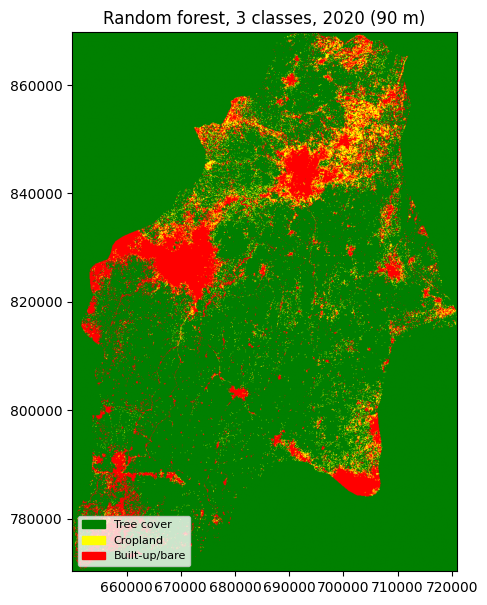

In [9]:
# Map the three classes over the study area (every 3rd pixel, 90 m, for speed)
rf3.fit(X, y3)
comp_c = clip_to_area(comp)          # keep only pixels inside the study-area boundary
stack = np.stack([comp_c[v].values for v in feat_names], axis=-1)[::3, ::3]
flat = stack.reshape(-1, len(feat_names))
valid = ~np.isnan(flat).any(axis=1)
out = np.full(flat.shape[0], -1)
out[valid] = rf3.predict(flat[valid])
out = np.ma.masked_where(out < 0, out).reshape(stack.shape[:2])

share = np.bincount(out.compressed(), minlength=3) / out.count() * 100
print("Mapped share of area inside the boundary (%):", dict(zip(labels3, share.round(1))))
print("Thesis Table 4.2, 2020 (approx.): Tree cover 86, Cropland 2, Built-up/bare 11")

colors3 = ["green", "yellow", "red"]
labels3 = ["Tree cover", "Cropland", "Built-up/bare"]
xv, yv = comp_c.x.values, comp_c.y.values
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(out, cmap=ListedColormap(colors3), vmin=-0.5, vmax=2.5,
          extent=[xv[0], xv[-1], yv[-1], yv[0]])
ax.set_title("Random forest, 3 classes, 2020 (90 m)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors3], labels3,
          loc="lower left", fontsize=8)
plt.show()

**What this shows.** The six-class model is barely better than guessing: dense forest, light forest and plantation have similar Landsat spectra and are mixed up, as the NDVI curves already suggested. This is why the thesis classification relied on field-based ground truthing and image interpretation. The three-class version is a fairer test (see the accuracy and the confusion matrix above). Training points were chosen as field sample sites, not in proportion to area, so mapped class shares can differ from the thesis map.
Inside the 4,259 km² study-area boundary, the three-class random forest maps 85.1% tree cover, 4.2% cropland and 10.7% built-up/bare in 2020, close to thesis Table 4.2 (about 86%, 2% and 11%). This is a consistency check, not an accuracy assessment: the thesis map covers a smaller area (about 3,272 km²), the model was trained on only about 40 field points, and the map was not validated against independent points.
With leave-one-out cross-validation on about 40 field points, the three-class random forest reaches 60% accuracy, only modestly above the 52% obtained by always guessing the largest class (tree cover). Tree cover is recognised well (19 of 21 points), built-up/bare moderately (5 of 11), and cropland not at all (0 of 8), so the mapped cropland share should not be interpreted.

## Limitations

- Single-date (dry-season) composites from different sensors and seasons; absolute NDVI is not comparable between years; no usable scene for 1992.
- About 40 ground-truth points, all from 2020, so they cannot label earlier years. Leave-one-out accuracy is probably optimistic because nearby points are spatially correlated.

- Next time: add a wet-season composite (seasonality helps separate plantations from forest), and store results as a gridded NetCDF with Xarray/Dask.

Data: Landsat Collection 2 Level-2 via Microsoft Planetary Computer; admin boundaries FAO GAUL 2015; ground-truth points from my MSc fieldwork.

- **Sampling caution:** Pixel-based leave-one-out scores are exploratory and not independent spatial validation. Do not use the three-class map as a reliable cropland area estimate.
